# DIN attention assigned to OOD history companies

This histogram compares the target-conditioned DIN attention assigned to OOD companies in the user's company history for the `none`, `kar_base`, and `kar_ours` variants. Attention is normalized relative to sequence length as `attention lift = mean OOD softmax attention × history length`. A lift of 1 is uniform attention, above 1 is above-uniform attention, and below 1 is below-uniform attention.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path("/home/leeze/career_experiments_2")
DATA_DIR = ROOT / "data" / "din_attention_ood_company"
COLUMN = "ood_company_attention_softmax"

FILES = {
    "none": DATA_DIR / "din_attention_ood_company_none.csv",
    "kar_base": DATA_DIR / "din_attention_ood_company_kar_base.csv",
    "kar_ours": DATA_DIR / "din_attention_ood_company_kar_ours.csv",
}
COLORS = {"none": "#7f7f7f", "kar_base": "#2878b5", "kar_ours": "#d62728"}
NUM_BINS = 40

In [2]:
attention = {}
results = {}
for name, path in FILES.items():
    if not path.is_file():
        raise FileNotFoundError(f"Missing input file: {path}")
    frame = pd.read_csv(
        path,
        usecols=["ood_row_index", "target_company", "predicted_company", "ood_company_names", COLUMN, "history_companies"],
    )
    frame["ood_company_names"] = frame["ood_company_names"].map(json.loads)
    ood_attention_arrays = frame[COLUMN].map(json.loads)
    if any(len(names) != len(weights) or not names for names, weights in zip(frame["ood_company_names"], ood_attention_arrays)):
        raise ValueError(f"{path.name} contains misaligned or empty OOD name/attention arrays")
    if any(not 0.0 <= value <= 1.0 for weights in ood_attention_arrays for value in weights):
        raise ValueError(f"{path.name} contains attention values outside [0, 1]")
    values = ood_attention_arrays.map(np.mean)
    history_lengths = frame["history_companies"].map(lambda value: len(json.loads(value)))
    if (history_lengths <= 0).any():
        raise ValueError(f"{path.name} contains an empty company history")
    frame["attention_lift"] = values * history_lengths
    results[name] = frame
    attention[name] = frame["attention_lift"].to_numpy()

reference_rows = results["none"]["ood_row_index"].tolist()
if any(frame["ood_row_index"].tolist() != reference_rows for frame in results.values()):
    raise ValueError("The three result files are not aligned by OOD row index")

pd.DataFrame(
    {
        name: {"samples": len(values), "mean": values.mean(), "median": np.median(values)}
        for name, values in attention.items()
    }
).T

,samples,mean,median
none,2756.0,0.994974,0.992748
kar_base,2756.0,1.006383,1.003331
kar_ours,2756.0,1.003424,1.000000


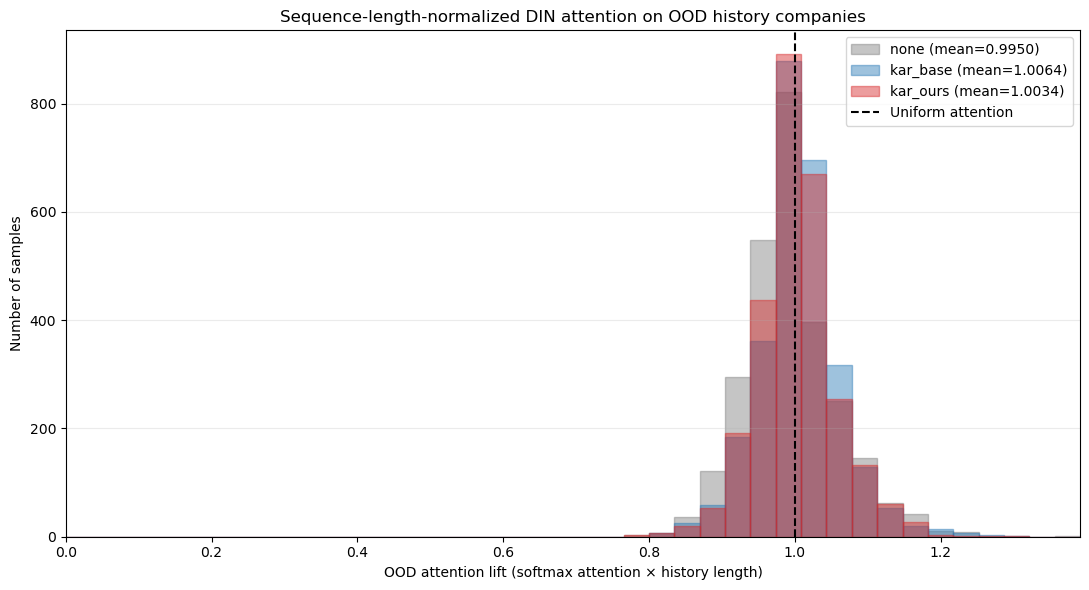

In [3]:
upper_limit = max(values.max() for values in attention.values())
plot_upper_limit = upper_limit * 1.02
bins = np.linspace(0.0, plot_upper_limit, NUM_BINS + 1)

fig, ax = plt.subplots(figsize=(11, 6))
for name, values in attention.items():
    ax.hist(
        values,
        bins=bins,
        alpha=0.45,
        color=COLORS[name],
        edgecolor=COLORS[name],
        label=f"{name} (mean={values.mean():.4f})",
    )

ax.axvline(1.0, color="black", linestyle="--", linewidth=1.5, label="Uniform attention")
ax.set_title("Sequence-length-normalized DIN attention on OOD history companies")
ax.set_xlabel("OOD attention lift (softmax attention × history length)")
ax.set_ylabel("Number of samples")
ax.set_xlim(0.0, plot_upper_limit)
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

## Attention on rows where KAR-Ours succeeds

This comparison uses the same subset for all three variants: rows where `kar_ours` ranks the correct target company first.

,samples,mean,median
none,1274.0,1.012593,1.000000
kar_base,1274.0,0.990394,0.996964
kar_ours,1274.0,0.989128,0.994398


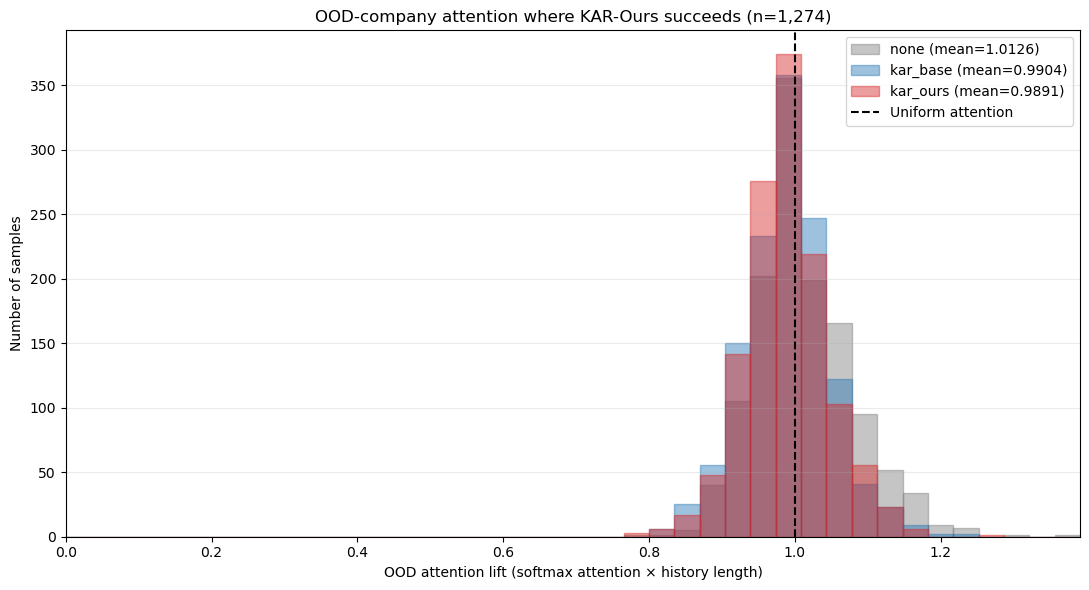

In [4]:
kar_ours_success_mask = results["kar_ours"]["predicted_company"].eq(
    results["kar_ours"]["target_company"]
)
kar_ours_success_attention = {
    name: frame.loc[kar_ours_success_mask, "attention_lift"].to_numpy()
    for name, frame in results.items()
}

kar_ours_success_summary = pd.DataFrame(
    {
        name: {
            "samples": len(values),
            "mean": values.mean(),
            "median": np.median(values),
        }
        for name, values in kar_ours_success_attention.items()
    }
).T
display(kar_ours_success_summary)

upper_limit = max(values.max() for values in kar_ours_success_attention.values())
plot_upper_limit = upper_limit * 1.02
bins = np.linspace(0.0, plot_upper_limit, NUM_BINS + 1)

fig, ax = plt.subplots(figsize=(11, 6))
for name, values in kar_ours_success_attention.items():
    ax.hist(
        values,
        bins=bins,
        alpha=0.45,
        color=COLORS[name],
        edgecolor=COLORS[name],
        label=f"{name} (mean={values.mean():.4f})",
    )

ax.axvline(1.0, color="black", linestyle="--", linewidth=1.5, label="Uniform attention")
ax.set_title(
    f"OOD-company attention where KAR-Ours succeeds (n={kar_ours_success_mask.sum():,})"
)
ax.set_xlabel("OOD attention lift (softmax attention × history length)")
ax.set_ylabel("Number of samples")
ax.set_xlim(0.0, plot_upper_limit)
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

## Attention on each model's own successful rows

Each row below uses a different subset: only the samples for which that particular model ranks the correct company first.

In [5]:
own_success_summary = {}
for name, frame in results.items():
    successful_values = frame.loc[
        frame["predicted_company"].eq(frame["target_company"]),
        "attention_lift",
    ]
    own_success_summary[name] = {
        "mean": successful_values.mean(),
        "median": successful_values.median(),
    }

pd.DataFrame.from_dict(own_success_summary, orient="index")

,mean,median
none,1.022063,1.013384
kar_base,0.986066,0.988742
kar_ours,0.989128,0.994398


## Attention when the target differs from every OOD history company

This shared subset excludes rows where the target company is equal to any OOD company occurrence in that row's history.

,samples,mean,median
none,2051.0,1.009547,1.001518
kar_base,2051.0,0.991136,0.995692
kar_ours,2051.0,0.986184,0.992824


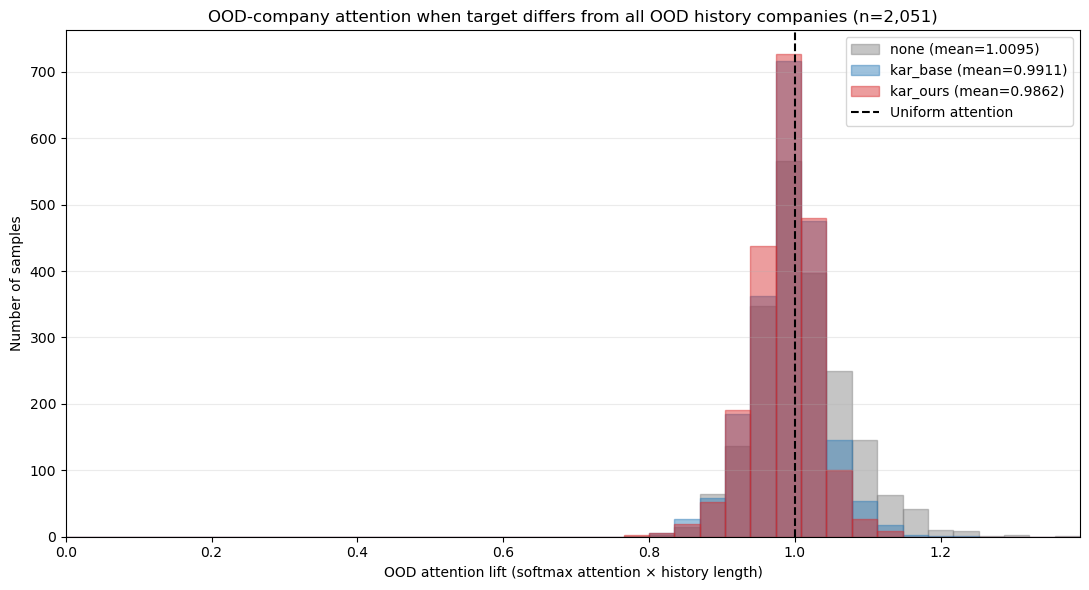

In [6]:
target_different_mask = pd.Series(
    [
        target not in ood_names
        for target, ood_names in zip(
            results["kar_ours"]["target_company"],
            results["kar_ours"]["ood_company_names"],
        )
    ],
    index=results["kar_ours"].index,
)
target_different_attention = {
    name: frame.loc[target_different_mask, "attention_lift"].to_numpy()
    for name, frame in results.items()
}

target_different_summary = pd.DataFrame(
    {
        name: {
            "samples": len(values),
            "mean": values.mean(),
            "median": np.median(values),
        }
        for name, values in target_different_attention.items()
    }
).T
display(target_different_summary)

upper_limit = max(values.max() for values in target_different_attention.values())
plot_upper_limit = upper_limit * 1.02
bins = np.linspace(0.0, plot_upper_limit, NUM_BINS + 1)

fig, ax = plt.subplots(figsize=(11, 6))
for name, values in target_different_attention.items():
    ax.hist(
        values,
        bins=bins,
        alpha=0.45,
        color=COLORS[name],
        edgecolor=COLORS[name],
        label=f"{name} (mean={values.mean():.4f})",
    )

ax.axvline(1.0, color="black", linestyle="--", linewidth=1.5, label="Uniform attention")
ax.set_title(
    f"OOD-company attention when target differs from all OOD history companies (n={target_different_mask.sum():,})"
)
ax.set_xlabel("OOD attention lift (softmax attention × history length)")
ax.set_ylabel("Number of samples")
ax.set_xlim(0.0, plot_upper_limit)
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()